# Module 04 — Saturday: Deep Learning, PyTorch and Model Training

Run every cell from top to bottom. This session includes the former Wednesday foundations and Saturday training lessons. Sunday contains CNNs and applications.


## Run this notebook

Use the Code folder as your working directory. The project uses the original Module 3 student CSV.

## Before the code: the basic terms

**Machine learning** learns a mapping from examples. A **feature** is one input measurement and a **label** is its known answer. A **neural network** combines layers of weighted calculations; training changes its weights and biases. **Deep learning** uses multiple learned layers to build intermediate representations. **Inference** uses the learned values to predict without updating them.

You already used features, labels and train/test splits in Module 3. Today we open the neural-network calculations one at a time.

## Local setup: Python 3.15.0

In **Windows Command Prompt**, run these commands once. Do not put terminal commands into a normal Python cell.

```bat
py -3.15 -m venv .venv
.venv\Scripts\activate
python -m pip install --upgrade pip
python -m pip install numpy==2.5.4
python -m pip install torch==2.15.0 --index-url https://download.pytorch.org/whl/cpu
```

Choose this environment as your Jupyter kernel. `sys.executable` in the first block identifies the active interpreter. Colab supplies its own Python version. If `import torch` fails on Windows, run `check_environment.py`; an installed package can still have a missing native DLL dependency.

## Setup

### Foundation 01 — Check the Python interpreter

**What it means:** An interpreter is the program running your Python code. A notebook must use the environment where PyTorch is installed.

Run only this block first, then inspect its output before continuing.

In [1]:
import sys  # Access interpreter details and command-line arguments.
print(sys.version)  # Print the interpreter release.
print(sys.executable)  # Print the full interpreter path.


3.15.1 (tags/v3.15.1:c37e74c, Oct 21 2026, 06:24:08) [MSC v.1951 64 bit (AMD64)]
c:\Users\au84b\AppData\Local\Python\pythoncore-3.15-64\python.exe


**Code walkthrough**

- sys.version reports the Python release.
- sys.executable shows the exact interpreter path.

**How to read the result:** For the requested local setup, the version should start with 3.15.0. Colab controls its own Python version.

### Foundation 02 — Import PyTorch

**What it means:** PyTorch represents numbers as tensors and calculates gradients used to train neural networks.

Run only this block first, then inspect its output before continuing.

In [2]:
import torch  # Import PyTorch for tensors and training.
from torch import nn  # Import layers and loss functions.
torch.manual_seed(42)  # Make PyTorch randomness repeatable.
torch.set_num_threads(2)  # Limit CPU work to two threads.
print(torch.__version__)  # Print the PyTorch version that actually imported.


2.15.0+cpu


**Code walkthrough**

- import torch makes the torch namespace available.
- nn is a shorter name for torch.nn.
- manual_seed fixes the random-number sequence, not the correct answer.

**How to read the result:** A version prints only if PyTorch imports successfully. pip show alone does not test native DLL loading.

## PyTorch: purpose, applications and benefits

### What is PyTorch?
PyTorch is a free, open-source framework for building machine-learning models, especially deep neural networks.
- A framework provides reusable tools so you can focus on the model and the data.
- PyTorch is the project name. Its main Python package is called torch.
- You write Python code to describe the model, then use the framework to learn from examples.

### What developers use PyTorch for
Developers use PyTorch throughout a model’s life: creating an idea, adapting a trained model, and using it to make predictions.
- Build a custom model when a task needs a particular architecture or loss.
- Fine-tune pretrained weights on examples from your own task.
- Run trained models in an application after checking accuracy, speed and resource needs.

### Why developers choose PyTorch
PyTorch combines familiar Python programming with tools that make neural-network experiments easier to build and inspect.
- Immediate execution lets you print intermediate values and debug a calculation.
- Automatic differentiation reduces the work of writing derivatives by hand.
- Accelerator support and pretrained-model libraries help larger projects. Small lessons can run on a CPU.

### Added operation A: CPU and GPU placement

A device is where a tensor’s calculations run. CUDA uses a compatible NVIDIA GPU when the installed PyTorch build supports it.

A GPU can speed up large parallel workloads. Moving tiny arrays may cost more than it saves.

**Expected result:** The first line prints cpu or cuda:0. Moving back to the CPU keeps the values [0., 1., 2., 3.].

In [ ]:

device = torch.device(  # Use CUDA when available; otherwise use the CPU.
    'cuda' if torch.cuda.is_available() else 'cpu')  # Use CUDA only when this PyTorch build and machine can access it.

probe = torch.arange(4, dtype=torch.float32)  # arange(4) creates 0, 1, 2, 3.
probe = probe.to(device)  # Move this tensor to the chosen device and keep the returned tensor.

print(probe.device)  # Read where probe currently lives: CPU, or a CUDA device such as cuda:0.
print(probe)  # Copy the values to CPU memory for display.


cpu
tensor([0., 1., 2., 3.])


In [12]:
t1=torch.tensor([11.,22.,33.,44.])
print(t1.dtype)


torch.float32


In [5]:
import numpy as np
arr = np.array([20,30,40,50])
t2=torch.tensor(arr)
print(arr)
print(t2)

[20 30 40 50]
tensor([20, 30, 40, 50])


### Added operation B: Addition, subtraction and division

These operations work on matching tensor entries. Here, the first value combines with the first value, and the second with the second.

Use nonzero denominators for this division example. The original lesson already covers multiplication.

**Expected result:** Addition: [3., 6.]
Subtraction: [1., 2.]
Division: [2., 2.]

In [13]:
left = torch.tensor([2., 4.])  # Build a one-dimensional floating-point tensor with two entries.
right = torch.tensor([1., 2.])  # Build the second tensor with the same shape.
print(left + right)  # Add matching positions: 2+1 and 4+2 produce tensor([3., 6.]).
print(left - right)  # Subtract matching positions: 2-1 and 4-2 produce tensor([1., 2.]).
print(left / right)  # Divide matching positions: 2/1 and 4/2 produce tensor([2., 2.]).


tensor([3., 6.])
tensor([1., 2.])
tensor([2., 2.])


### Added operation C: Mean, maximum and its position

A reduction summarizes several values. argmax returns the index of the largest value, rather than the value itself.

In a class-score vector, argmax identifies a class position. It does not supply a class name.

**Expected result:** Mean is about 0.3333.
Maximum is about 0.7.
argmax is 1, because indexing starts at zero.

In [15]:
scores = torch.tensor([0.2, 0.7, 0.1])  # Store three scores in a one-dimensional tensor.
print(scores.mean())  # Print the average as a Python number.
print(scores.max().item())  # Print the highest score.
print(scores.argmax().item())  # argmax gives the largest score's index (1); item returns a Python integer.


tensor(0.3333)
0.699999988079071
1


### Added operation D: Reshape and transpose

reshape changes how entries are arranged into dimensions. Transpose swaps axes, changing which entries appear in each row.

Reshape keeps the total number of entries: 6 = 2 × 3. Transpose is a different operation.

**Expected result:** reshape gives rows [0, 1, 2] and [3, 4, 5]. Transpose gives rows [0, 3], [1, 4] and [2, 5].

In [19]:
flat = torch.arange(6)  # Create the integer sequence 0 through 5, excluding the endpoint 6.
matrix = flat.reshape(2, 3)  # Reshape six entries into two rows and three columns.
print(matrix)  # Read the reshaped rows: [0, 1, 2] followed by [3, 4, 5].
print(matrix.T)  # Transpose swaps rows and columns: [2, 3] becomes [3, 2].

tensor([[0, 1, 2],
        [3, 4, 5]])
tensor([[0, 3],
        [1, 4],
        [2, 5]])


### Added operation E: NumPy and tensor conversion

NumPy interoperability lets existing numerical data enter a PyTorch workflow. Some conversions share the same CPU memory.

For a tensor with gradients or on a GPU, use tensor.detach().cpu().numpy() to obtain a NumPy array.

**Expected result:** Both print [9., 2.]. Changing shared changed the NumPy array too. Use shared.clone() for an independent tensor.

In [ ]:
import numpy as np  # NumPy arrays can share CPU memory with PyTorch tensors.
array = np.array([1., 2.], dtype=np.float32)  # Make a float32 NumPy array.
print(array)
shared = torch.from_numpy(array)  # Shares memory: editing this tensor also changes the NumPy array.
shared[0] = 9.  # Replace the first shared-memory entry with 9.
print(array)  # Confirm the shared NumPy array changed.
print(shared.numpy())  # Convert the CPU tensor back to a NumPy view.

[1. 2.]
[9. 2.]
[9. 2.]


## Tensors

### Foundation 03 — A Python list becomes a tensor

**What it means:** A tensor is a container of numbers. One student can be represented by two measurements in a fixed order.

Run only this block first, then inspect its output before continuing.

In [22]:
measurements = [6.0, 85.0]  # Keep feature order fixed: study hours, then attendance.
student = torch.tensor(measurements, dtype=torch.float32)  # Create a floating-point tensor with shape [2].
print(student)  # Read the actual input measurements, tensor([6., 85.]).

tensor([ 6., 85.])


**Code walkthrough**

- A list stores the input measurements.
- torch.tensor converts those values to a tensor.
- float32 stores floating-point values suitable for the model.

**How to read the result:** The tensor contains 6 and 85. These are input measurements, not predictions.

**Practice:** Why must attendance stay in the second position?

**Solution and reasoning:** The model learns one weight for each input position. Swapping columns changes their meaning.

### Foundation 04 — Rows, columns and shape

**What it means:** A feature matrix is a two-dimensional tensor. Every row is an example and every column is a feature.

Run only this block first, then inspect its output before continuing.

In [23]:
examples = torch.tensor([[2., 45.], [6., 85.], [4., 72.]])  # Shape [3, 2]: three students, two features each.
print(examples)  # Display all three rows.
print(examples.shape)  # shape returns torch.Size([3, 2]).
print(examples.dtype)  # dtype reports the element type, normally torch.float32 here.
print(examples.device)  # device reports the memory location.


tensor([[ 2., 45.],
        [ 6., 85.],
        [ 4., 72.]])
torch.Size([3, 2])
torch.float32
cpu


**Code walkthrough**

- The outer list contains three student rows.
- shape gives the size of each axis.
- dtype describes number storage and device describes where computation happens.

**How to read the result:** shape is torch.Size([3, 2]). There are three students and two features. The default device here is CPU.

**Practice:** What shape represents five students with two features?

**Solution and reasoning:** [5, 2]. The first dimension counts rows, not feature names.

### Foundation 05 — Select rows and columns

**What it means:** Indexing selects part of a tensor. Python starts counting positions at zero.

Run only this block first, then inspect its output before continuing.

In [25]:
print(examples[0])  # Select the first student row.
print(examples[:, 1])  # Select study hours for every student; indexing starts at zero.
print(examples[:2])  # Slice rows 0 and 1, excluding endpoint 2.


tensor([ 2., 45.])
tensor([45., 85., 72.])
tensor([[ 2., 45.],
        [ 6., 85.]])


**Code walkthrough**

- [0] selects the first row.
- : means all positions on that axis.
- :2 stops before index 2.

**How to read the result:** The hours column is [2, 6, 4]. Selecting a column this way produces a one-dimensional tensor.

## Neuron

### Foundation 06 — Multiply inputs by weights

**What it means:** A weight controls how strongly one input affects a neuron. These fixed weights illustrate the calculation before training.

Run only this block first, then inspect its output before continuing.

In [27]:
students= torch.tensor([8.0 , 63.0])
weights = torch.tensor([0.3, 0.02])  # Use example weights for hours and attendance.
products = students * weights  # Multiply each feature by its corresponding weight.
print(products)  # Show each feature's weighted contribution.
print(products.sum())  # sum adds the two contributions, approximately 3.5.


tensor([2.4000, 1.2600])
tensor(3.6600)


**Code walkthrough**

- The first weight belongs to hours and the second to attendance.
- * multiplies matching positions.
- sum adds the weighted contributions.

**How to read the result:** Contributions are approximately [1.8, 1.7]. Their sum is 3.5.

### Foundation 07 — Add a bias and an activation

**What it means:** A bias shifts the weighted sum. ReLU keeps positive values and changes negative values to zero.

Run only this block first, then inspect its output before continuing.

In [30]:
bias = -2.0  # Choose an illustrative bias that shifts the weighted sum.
z = products.sum() + bias  # Add the weighted inputs and bias.
activation = torch.relu(z)  # ReLU keeps positive values and replaces negative values with zero.
print('Weighted sum plus bias:', z.item())  # item reads the scalar pre-activation as a Python number.
print('ReLU output:', activation.item())  # Display the post-ReLU value, approximately 1.5.


Weighted sum plus bias: 1.6600000858306885
ReLU output: 1.6600000858306885


**Code walkthrough**

- z is the weighted sum plus the bias.
- torch.relu applies max(0, z).
- item extracts one scalar as a Python number.

**How to read the result:** z and the ReLU output are both approximately 1.5. ReLU is not a probability.

**Practice:** What is ReLU(-1.5)?

**Solution and reasoning:** 0. A negative weighted sum becomes zero under ReLU.

### Foundation 08 — A logit becomes a probability

**What it means:** A logit is an unrestricted score. Sigmoid maps it to a value between zero and one.

Run only this block first, then inspect its output before continuing.

## Turn a score into Pass or Fail

The network returns a raw score. Sigmoid puts it on a 0–1 scale. A cutoff turns that value into a class.

**How the code works**

- At 0.5 or higher, predict 1. Below 0.5, predict 0.
- This hand-picked score is a practice example.

**Read the result**

Output is about 0.818 and class 1. In our project, class 1 means Pass.

In [34]:
logit = torch.tensor([1])  # Create an example raw model score.
probability = torch.sigmoid(logit)  # Sigmoid maps a raw score to a value between 0 and 1.
prediction = (probability >= 0.9).int()  # Convert the threshold result to 0 or 1.
print(probability, prediction)  # Show the probability and final class.


tensor([0.7311]) tensor([0], dtype=torch.int32)


## Give the layer one student

PyTorch usually receives a group of rows called a batch. Even one student can be a batch.

**How the code works**

- The nested list makes one row with two features.
- The layer starts with two weights and one bias. Calling the layer computes `7.5 * w1 + 54.0 * w2 + bias`.
- `one_score` stores the raw result. The initial weights are random, so its value depends on the layer.

**Read the result**

The input is [1, 2], one student and two features. The output is [1, 1], one score for that student.

In [48]:
one_row = torch.tensor([[7.5, 54.0]])  # Store one student's hours and attendance.
one_layer = nn.Linear(2, 1)  # Create two weights and one bias.
one_score = one_layer(one_row)  # Multiply inputs by weights, then add bias.
print(one_row.shape, one_score.shape)  # Verify [1, 2] becomes [1, 1].
print(one_row)
print(one_score)

torch.Size([1, 2]) torch.Size([1, 1])
tensor([[ 7.5000, 54.0000]])
tensor([[8.3951]], grad_fn=<AddmmBackward0>)


## See what a hidden layer changes

A hidden layer creates intermediate values. ReLU changes negatives to zero before the final layer calculates the score.

**How the code works**

- ReLU([-2, 1, 3]) gives [0, 1, 3].
- The second layer expects four inputs because the first produces four.

**Read the result**

The input becomes four hidden values and then one score. Random weights have not learned anything about students yet.

In [49]:
hidden_layer = nn.Linear(2, 4)  # Map two features to four hidden values.
hidden = hidden_layer(one_row)  # Produce four values for the student.
hidden = torch.relu(hidden)  # Replace negative hidden values with zero.
output_layer = nn.Linear(4, 1)  # Turn four hidden values into one score.
print(hidden.shape, output_layer(hidden).shape)  # Compare hidden and final output shapes.

torch.Size([1, 4]) torch.Size([1, 1])


## Which prediction is closer?

Loss is a number that measures how wrong the model is. With a Pass label of 1, a high Pass score should have lower loss.

**How the code works**

- Use the raw score with BCEWithLogitsLoss. It applies sigmoid internally.
- The predicted score and the label have the same shape.

**Read the result**

The losses are about 2.13 and 0.13. The positive score is a better fit for the Pass label.

In [65]:
loss_fn = nn.BCEWithLogitsLoss()  # Compare raw scores with binary labels.
actual = torch.tensor([[1.]])  # Set the true label to Pass.
low_score = torch.tensor([[-2.]])  # Use a score favoring Fail.
high_score = torch.tensor([[2.]])  # Use a score favoring Pass.
print(loss_fn(low_score, actual).item())  # Show the loss for a wrong-leaning score.
print(loss_fn(high_score, actual).item())  # Show the loss for a correct-leaning score.


2.1269280910491943
0.12692801654338837


## One gradient update by hand

If the current weight is 2 and the target weight is 4, squared error measures how far apart they are.

**How the code works**

- At weight 2 the gradient is -4.
- Subtracting 0.25 times -4 moves the weight to 3.
- The new squared error is 1.

**Read the result**

Output is 3.0 and 1.0. The update reduced the loss from 4 to 1.

In [79]:
weight = torch.tensor(2., requires_grad=True)  # Start at 2 and track its gradient.
toy_loss = (weight - 4).square()  # Measure squared distance from the target.
toy_loss.backward()  # Calculate gradients of the score with respect to the weights and bias..
with torch.no_grad():  # Skip gradient tracking.
    weight -= 0.25 * weight.grad  # Move the weight against the gradient.
print(weight.item(), (weight - 4).square().item())  # Show the new weight and squared error.

3.0 1.0


## Read the Module 3 CSV

Each row describes one student. Read the original CSV before choosing the two input columns and the target.

**How the code works**

- `pd.read_csv()` loads the CSV into the same kind of DataFrame used in Module 2.
- The original CSV contains 280 records.
- Keep passed as the target and exclude final_score, which leaks outcome information.

**Read the result**

The first student studied 7.5 hours, had 54% attendance, and has passed = 0.

In [1]:
from pathlib import Path  # Work with file paths.
import pandas as pd  # Load and organize tabular data.

csv_path = Path('../../Week-3/Day-3/student_learning.csv')  # Point to the student dataset.
students = pd.read_csv(csv_path)  # Load one student per row.
print(students.shape)  # Check row and column counts.
print(students.head(1))  # Preview the first student.


(280, 7)
   hours_studied  attendance  practice_tests  sleep_hours study_method  \
0            7.5          54               0          5.6        video   

   final_score  passed  
0           48       0  


## Select the feature and target columns

The network sees two inputs per row. The label stays separate and tells the loss function what the correct answer is.

**How the code works**

- `X` selects study hours and attendance by name.
- `y = students[["passed"]]` keeps the target as a one-column DataFrame.
- The shapes are [280, 2] and [280, 1].

**Read the result**

`value_counts(normalize=True)` reports the share of students in each class.

In [2]:
features = ['hours_studied', 'attendance']  # Keep the model's feature order.
X = students[features]  # Select the two input columns.
y = students[['passed']]  # Keep the target as a one-column DataFrame.
print(X.shape, y.shape)  # Check feature and target dimensions.
print(y['passed'].value_counts(normalize=True))  # Inspect the class proportions.


(280, 2) (280, 1)
passed
0    0.560714
1    0.439286
Name: proportion, dtype: float64


## Split before learning statistics

Training data updates weights, validation data guides model selection, and test data checks the selected model once.

**How the code works**

- `train_test_split()` takes the pandas feature and target tables together, so rows and labels stay paired.
- First reserve 30% of rows, then divide those rows equally into validation and test sets.
- `random_state=42` repeats the split and `stratify` keeps class proportions close.

**Read the result**

There are 196 training, 42 validation and 42 test records. The two held-out sets each contain 15% of the original rows.

In [10]:
from sklearn.model_selection import train_test_split  # Split rows and labels together.
import numpy as np
import torch

X_train_df, X_holdout, y_train_df, y_holdout = train_test_split(  # Reserve 30% for validation and testing.
    X, y, test_size=0.30, random_state=42, stratify=y['passed']  # Repeat the split and keep class proportions close.
)
X_valid_df, X_test_df, y_valid_df, y_test_df = train_test_split(  # Divide the held-out rows in half.
    X_holdout, y_holdout, test_size=0.50, random_state=42, stratify=y_holdout['passed']  # Keep labels balanced across both halves.
)
print(len(X_train_df), len(X_valid_df), len(X_test_df))  # Show train, validation, and test counts.


196 42 42


## Convert labels to tensors

**How the code works**

Keep the labels as float32 tensors with shape [number of students, 1]. The model returns one score per student. The input features are scaled in the next step.


In [11]:
def to_float_tensor(frame):  # Convert numeric labels for PyTorch.
    values = frame.to_numpy(dtype=np.float32, copy=True)  # Keep the one-column shape.
    return torch.from_numpy(values)  # Wrap the NumPy array as a tensor.

y_train = to_float_tensor(y_train_df)  # Convert training labels.
y_valid = to_float_tensor(y_valid_df)  # Convert validation labels.
y_test = to_float_tensor(y_test_df)  # Convert test labels.
print(y_train.shape)  # Check that each student has one label.


torch.Size([196, 1])


## Standardize the input features

**How the code works**

Fit scikit-learn’s StandardScaler on the training DataFrame. Use the same scaler for validation and test features, then convert the scaled arrays to float32 tensors. Save the learned means and scales for new students.


In [12]:
from sklearn.preprocessing import StandardScaler  # Reuse the Module 3 scaler.

scaler = StandardScaler().fit(X_train_df)  # Learn scaling from training rows only.
X_train = torch.from_numpy(scaler.transform(X_train_df))  # Scale training features.
X_valid = torch.from_numpy(scaler.transform(X_valid_df))  # Reuse the same scaling.
X_test = torch.from_numpy(scaler.transform(X_test_df))  # Reuse the same scaling.
X_train, X_valid, X_test = X_train.float(), X_valid.float(), X_test.float()  # Match model dtype.
mean = torch.tensor(scaler.mean_, dtype=torch.float32)  # Keep the means for inference.
scale = torch.tensor(scaler.scale_, dtype=torch.float32)  # Keep the scales for inference.
print(X_train.mean(dim=0))  # Check that training feature means are near zero.
print(X_train.std(dim=0))  # Check that training feature scales are near one.

tensor([5.4739e-09, 7.2985e-09])
tensor([1.0026, 1.0026])


## Establish a majority-class baseline

**How the code works**

Fit scikit-learn’s DummyClassifier on training labels. It always predicts the most frequent class. Use validation accuracy to measure the baseline.


In [13]:
from sklearn.dummy import DummyClassifier  # Build a majority-class baseline.
from sklearn.metrics import accuracy_score  # Count the fraction of correct labels.

baseline = DummyClassifier(strategy='most_frequent')  # Always predict the common class.
baseline.fit(X_train_df, y_train_df['passed'])  # Learn the common label from training data.
baseline_predictions = baseline.predict(X_valid_df)  # Predict on validation rows.
baseline_valid = accuracy_score(y_valid_df['passed'], baseline_predictions)  # Score the baseline.
print(baseline_predictions[0], round(baseline_valid, 3))  # Show its class and accuracy.


0 0.548


## Create batches with DataLoader

A batch is a small group processed together. A DataLoader iterates through the training examples in batches.

**How the code works**

- TensorDataset keeps each feature row paired with its label.
- batch_size=32 sets the maximum group size.
- shuffle changes row order; num_workers=0 keeps loading in this process.

**Read the result**

The first batch has [32, 2] features and [32, 1] labels. Seven batches cover 196 students; the last has four.

In [16]:
from torch.utils.data import TensorDataset, DataLoader  # Pair features with labels, then load aligned mini-batches.
training_rows = TensorDataset(X_train, y_train)  # Keep each feature row paired with its label.
train_loader = DataLoader(training_rows, batch_size=32,  # Load at most 32 paired students per batch; the last batch may be smaller.
                          shuffle=True, num_workers=0)  # Reshuffle training rows.
xb, yb = next(iter(train_loader))  # Fetch one batch of features and labels.
print(xb.shape, yb.shape, len(train_loader))  # A full batch has shapes [32, 2] and [32, 1].
# batches=list(train_loader) #To access each batch one by one
# xb,yb=batches[6]
# print(xb)
for batches ,(xb,yb) in enumerate(train_loader): #To access all batches
    print("batch number:\n",batches,xb)


torch.Size([32, 2]) torch.Size([32, 1]) 7
batch number:
 0 tensor([[ 0.8652,  0.1492],
        [-0.8614,  0.7894],
        [-0.6362, -1.1314],
        [-0.4110,  1.5009],
        [-1.0866, -1.4159],
        [ 0.2647,  0.7894],
        [ 1.6910, -0.1354],
        [ 0.9778,  1.2163],
        [-1.0115, -0.5622],
        [ 0.9403,  0.2915],
        [ 0.8652, -0.0642],
        [ 0.1145,  1.5009],
        [ 0.9028,  1.1452],
        [-1.1617, -0.6334],
        [ 1.6159, -0.0642],
        [ 0.0394,  1.3586],
        [-0.8614, -1.2025],
        [-0.9740,  0.5049],
        [-1.4619, -1.0602],
        [-1.6121, -1.5582],
        [-0.6362,  0.7894],
        [-1.5745, -0.8468],
        [-0.1107, -0.3488],
        [-0.6737,  0.1492],
        [-1.2743,  1.5009],
        [ 1.1655,  1.2163],
        [ 1.0154, -0.4199],
        [ 0.4899, -1.2025],
        [-0.0356,  0.6472],
        [-1.0491, -1.6293],
        [-0.8614, -0.2777],
        [ 1.5033, -0.5622]])
batch number:
 1 tensor([[ 0.5274,  1.4297],

## Build the same model as one module

nn.Module groups the layers and defines their order. The model takes two features and gives one Pass score.

**How the code works**

- Two features go into eight hidden values.
- The last layer returns one raw score for each row.

**Read the result**

Two students give output shape [2, 1]. The first training run uses dropout 0.0.

In [18]:
from torch import nn
class StudentMLP(nn.Module):  # Define the student classifier.
    def __init__(self, dropout=0.0):  # Set up the model layers.
        super().__init__()  # Initialize the parent PyTorch module.
        self.hidden = nn.Linear(2, 8)  # Map two features to eight hidden values.
        self.activation = nn.ReLU()  # Keep positive hidden values.
        self.dropout = nn.Dropout(dropout)  # Randomly drop hidden values during training.
        self.output = nn.Linear(8, 1)  # Map eight hidden values to one logit.

    def forward(self, x):  # Turn feature rows into raw scores.
        hidden = self.activation(self.hidden(x))  # Compute hidden activations.
        return self.output(self.dropout(hidden))  # Apply dropout and produce the final logit.

model = StudentMLP()  # Create the student classifier.
logits= model(X_train[:1])  # Check one score per student.
print(logits)
probabilities = torch.sigmoid(logits)
print(probabilities)

tensor([[0.2760]], grad_fn=<AddmmBackward0>)
tensor([[0.5686]], grad_fn=<SigmoidBackward0>)



  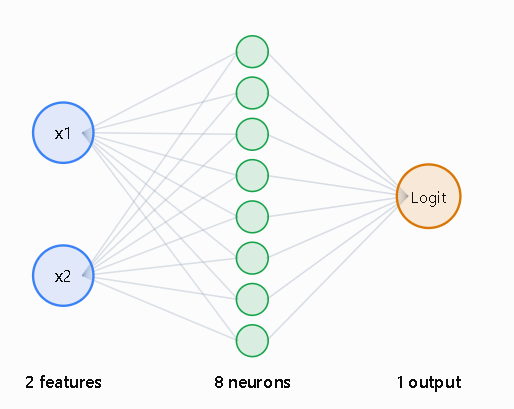

## Choose the loss and optimizer

The loss tells us how well the predictions match. The optimizer changes the weights. The learning rate controls the size of updates.

**How the code works**

- Pass labels are stored as float 0.0 or 1.0.
- Start with learning rate 0.01 for this small experiment.

**Read the result**

Adam is ready to update this model. The training loop calls it once per batch.

In [19]:
loss_fn = nn.BCEWithLogitsLoss()  # Compare raw scores with binary labels.
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)  # Set up Adam to update model weights.


## Perform one training update

One update calculates a prediction, measures loss, obtains gradients, then changes the model weights.

**How the code works**

- train selects training behavior, but does not itself learn anything.
- zero_grad avoids unwanted gradient accumulation.
- backward calculates gradients; step changes parameters.

**Read the result**

One batch has caused one optimizer step. One epoch will process every training batch.

In [20]:
# Save the original hidden-layer weights
weights_before = model.hidden.weight.detach().clone()
model.train()  # Enable training behavior.
optimizer.zero_grad()  # Clear gradients from the previous step.
logits = model(xb)  # Produce one raw score per student.
loss = loss_fn(logits, yb)  # Compare the raw scores with this batch's labels.
loss.backward()  # Calculate gradients for the current loss.
optimizer.step()  # Update weights using the gradients.
print(loss.item())  # Convert the scalar batch loss to a Python number for inspection.
weights_after = model.hidden.weight.detach().clone()
print(weights_before[0])
print(weights_after[0])

0.726401686668396
tensor([-0.0335, -0.2240])
tensor([-0.0335, -0.2240])


## Train one epoch

A batch is a small group of students. One epoch means training once on every batch in the loader.

**How the code works**

- The loop repeats the same four training steps for every batch.
- Multiply the batch loss by its row count so the shorter last batch counts fairly.

**Read the result**

This function returns the average loss per training student for one epoch.

In [23]:
def train_epoch(model, loader, optimizer):  # Update weights across one pass through training data.
    model.train()  # Enable training behavior.
    total_loss = 0.0  # Reset the loss accumulator for this epoch.
    for xb, yb in loader:  # Read a batch of inputs and labels.
        optimizer.zero_grad()  # Clear gradients from the previous step.
        loss = loss_fn(model(xb), yb)  # Compare this batch's scores with its labels.
        loss.backward()  # Calculate gradients for the current loss.
        optimizer.step()  # Update weights using the gradients.
        total_loss += loss.item() * len(yb)  # Weight the batch loss by row count.
    avg_loss=total_loss / len(loader.dataset)  # Average loss across training rows.
    return avg_loss
epoch_loss = train_epoch(model, train_loader, optimizer)
print("Training loss:", epoch_loss)
for epoch in range(20):     #To train for 20 epochs
    epoch_loss = train_epoch(model, train_loader, optimizer)
    print(f"Epoch {epoch+1}: Loss = {epoch_loss:.4f}")


Training loss: 0.45092911622962173
Epoch 1: Loss = 0.4387
Epoch 2: Loss = 0.4313
Epoch 3: Loss = 0.4268
Epoch 4: Loss = 0.4224
Epoch 5: Loss = 0.4171
Epoch 6: Loss = 0.4140
Epoch 7: Loss = 0.4132
Epoch 8: Loss = 0.4119
Epoch 9: Loss = 0.4106
Epoch 10: Loss = 0.4104
Epoch 11: Loss = 0.4104
Epoch 12: Loss = 0.4089
Epoch 13: Loss = 0.4076
Epoch 14: Loss = 0.4078
Epoch 15: Loss = 0.4085
Epoch 16: Loss = 0.4074
Epoch 17: Loss = 0.4062
Epoch 18: Loss = 0.4058
Epoch 19: Loss = 0.4051
Epoch 20: Loss = 0.4052


## Check validation without training

Validation rows measure progress on students the optimizer does not see. Switch to evaluation mode and calculate loss and accuracy.

**How the code works**

- eval() changes dropout and batch normalization behavior.
- inference_mode() skips gradient recording.

**Read the result**

Validation returns two numbers. Loss measures the scores. Accuracy counts correct classes.

In [24]:
def validate(model):  # Measure validation loss and accuracy.
    model.eval()  # Switch the model to evaluation mode.
    with torch.inference_mode():  # Run predictions without tracking gradients.
        scores = model(X_valid)  # Score the validation students.
        loss = loss_fn(scores, y_valid).item()  # Compute validation loss as a number.
        predictions = (scores.sigmoid() >= 0.5)  # Apply the Pass cutoff to each probability.
    accuracy = accuracy_score(y_valid_df, predictions.numpy().ravel())  # Score the validation labels.
    return loss, accuracy  # Return both validation metrics.

val_loss, val_accuracy = validate(model)
print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)


Validation Loss: 0.6082981824874878
Validation Accuracy: 0.7142857142857143


## Repeat and record the results

The outer loop counts epochs. After each epoch, record training loss and validation loss so you can compare them.

**How the code works**

- The training loop changes weights. The validation call checks them.
- The final test rows are still untouched.

**Read the result**

The last two printed values are validation loss and validation accuracy after epoch 20.

In [25]:
#to check loss and accuracy of every epoch
for epoch in range(20):
    train_loss = train_epoch(model, train_loader, optimizer)
    val_loss, val_accuracy = validate(model)
    print("Epoch:", epoch + 1)
    print("Training Loss:", round(train_loss, 4))
    print("Validation Loss:", round(val_loss, 4))
    print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
    print("--------------------")

Epoch: 1
Training Loss: 0.4056
Validation Loss: 0.6101
Validation Accuracy: 71.43 %
--------------------
Epoch: 2
Training Loss: 0.4056
Validation Loss: 0.6038
Validation Accuracy: 73.81 %
--------------------
Epoch: 3
Training Loss: 0.4047
Validation Loss: 0.6031
Validation Accuracy: 71.43 %
--------------------
Epoch: 4
Training Loss: 0.4046
Validation Loss: 0.6037
Validation Accuracy: 71.43 %
--------------------
Epoch: 5
Training Loss: 0.4042
Validation Loss: 0.6056
Validation Accuracy: 71.43 %
--------------------
Epoch: 6
Training Loss: 0.4039
Validation Loss: 0.6069
Validation Accuracy: 71.43 %
--------------------
Epoch: 7
Training Loss: 0.4044
Validation Loss: 0.6082
Validation Accuracy: 73.81 %
--------------------
Epoch: 8
Training Loss: 0.4039
Validation Loss: 0.6112
Validation Accuracy: 71.43 %
--------------------
Epoch: 9
Training Loss: 0.4047
Validation Loss: 0.6108
Validation Accuracy: 69.05 %
--------------------
Epoch: 10
Training Loss: 0.4048
Validation Loss: 0.6124

In [26]:
#Use for plotting
train_losses = []
valid_losses = []
for epoch in range(20):
    # Train the model
    train_loss = train_epoch(model, train_loader, optimizer)
    # Evaluate the model
    val_loss, val_accuracy = validate(model)
    # Save losses for plotting
    train_losses.append(train_loss)
    valid_losses.append(val_loss)
    # Print the results
    print("Epoch:", epoch + 1)
    print("Train Loss:", round(train_loss, 4))
    print("Validation Loss:", round(val_loss, 4))
    print("Accuracy:", round(val_accuracy * 100, 2), "%")
    print("--------------------")

Epoch: 1
Train Loss: 0.4015
Validation Loss: 0.6102
Accuracy: 71.43 %
--------------------
Epoch: 2
Train Loss: 0.4007
Validation Loss: 0.6108
Accuracy: 73.81 %
--------------------
Epoch: 3
Train Loss: 0.4048
Validation Loss: 0.6079
Accuracy: 71.43 %
--------------------
Epoch: 4
Train Loss: 0.4031
Validation Loss: 0.6068
Accuracy: 71.43 %
--------------------
Epoch: 5
Train Loss: 0.4011
Validation Loss: 0.6058
Accuracy: 71.43 %
--------------------
Epoch: 6
Train Loss: 0.4009
Validation Loss: 0.6047
Accuracy: 71.43 %
--------------------
Epoch: 7
Train Loss: 0.4014
Validation Loss: 0.6054
Accuracy: 69.05 %
--------------------
Epoch: 8
Train Loss: 0.4011
Validation Loss: 0.6054
Accuracy: 69.05 %
--------------------
Epoch: 9
Train Loss: 0.4014
Validation Loss: 0.6058
Accuracy: 71.43 %
--------------------
Epoch: 10
Train Loss: 0.4007
Validation Loss: 0.6062
Accuracy: 71.43 %
--------------------
Epoch: 11
Train Loss: 0.4006
Validation Loss: 0.6029
Accuracy: 69.05 %
------------------

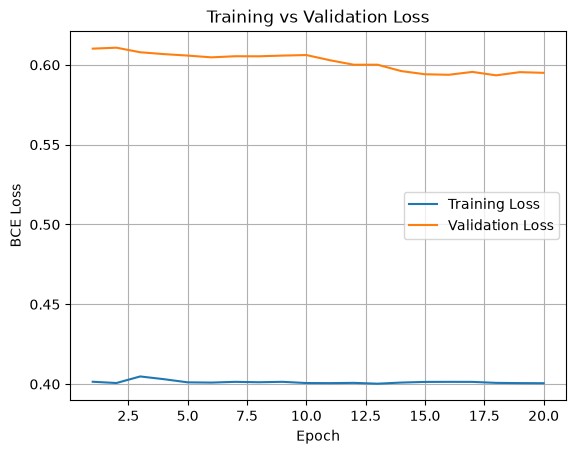

In [28]:
import matplotlib.pyplot as plt

plt.plot(range(1, 21), train_losses, label="Training Loss")
plt.plot(range(1, 21), valid_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
# plt.show()
# plt.savefig('module4_outputs/student2_learning_curves.png')  # Save the chart as a PNG.
# plt.close()  # Close the finished chart.


## Plot the two learning curves

A plot places the two losses on the same epoch axis so you can see when validation stops improving.

**How the code works**

- The chart uses the losses recorded by the loop.
- Training and validation losses must be read together.

**Read the result**

Open student_learning_curves.png. A widening gap suggests the model may fit training details that do not transfer.

## Save the measured learning curves

CSV preserves exact measured values. A chart can be created from these records without inventing additional data.

**How the code works**

- mkdir creates the output folder if needed.
- The DataFrame pairs both losses with their epoch number.
- `to_csv(index=False)` writes the three named columns without the DataFrame index.

**Read the result**

The CSV has a header and 20 measured epoch rows.

In [ ]:
output = Path('module4_outputs')  # Define the output folder.
output.mkdir(exist_ok=True)  # Create the folder if needed.
curve_table = pd.DataFrame({  # Make one row per training epoch.
    'epoch': range(1, len(train_losses) + 1),  # Number epochs starting at one.
    'training_loss': train_losses,  # Add the training loss history.
    'validation_loss': valid_losses,  # Add the matching validation losses.
})
curve_table.to_csv(output / 'learning_curves.csv', index=False)  # Save only the named columns.
print('Saved:', output / 'learning_curves.csv')  # Show where the table was saved.


## Read the two learning curves

Underfitting leaves a high training loss. Overfitting often shows up when training improves while validation gets worse.

**How the code works**

- Both curves improve: the model is still learning.
- Training improves but validation worsens: keep an earlier checkpoint.
- Both remain poor: check the inputs, model size, or learning rate.

**Read the result**

Pick a change you can test, such as the number of hidden units, dropout, or the learning rate.

## SGD, Adam, and AdamW

SGD takes a gradient step. Adam adapts step sizes using running gradient statistics. AdamW applies weight decay separately.

**How the code works**

- Each optimizer is connected to the supplied model parameters.
- This cell constructs optimizers but performs no training step.

**Read the result**

The three names print. Compare optimizers with fresh models, the same split, and documented settings.

In [ ]:
sgd = torch.optim.SGD(model.parameters(), lr=0.05)  # These optimizer recipes use different learning rates, not just different algorithms.
adam = torch.optim.Adam(model.parameters(), lr=0.01)  # Set up Adam with rate 0.01.
adamw = torch.optim.AdamW(model.parameters(), lr=0.01)  # Set up AdamW with rate 0.01.
print(type(sgd).__name__, type(adam).__name__)  # Show the SGD and Adam names.
print(type(adamw).__name__)  # Show AdamW's optimizer name.


## How Dropout behaves differently during training and evaluation in PyTorch.

Dropout randomly zeros some activations during training. Evaluation passes all activations through unchanged.

**How the code works**

- p=0.5 is the probability of zeroing one activation.
- Surviving training values are rescaled to preserve their expected magnitude.
- eval disables the random zeroing.

**Read the result**

Training values are 0 or 2 here; evaluation values are all 1. Weights are not permanently deleted.

In [ ]:
dropout = nn.Dropout(p=0.5)  # Randomly zero activations during training; evaluation passes them unchanged.
activations = torch.ones(2, 8)  # Supply a [2, 8] tensor of ones.
dropout.train()  # Enable Dropout's random masking behavior for the demonstration.
print('Training:', dropout(activations))  # Values become 0 or 2 in training mode.
dropout.eval()  # Disable Dropout's masking for evaluation.
print('Evaluation:', dropout(activations))  # Show the unchanged activations in evaluation mode.


## Add dropout and weight decay

Dropout changes hidden activations. Weight decay discourages large weights through the optimizer update.

**How the code works**

- Dropout is placed after a hidden activation.
- weight_decay is an optimizer setting, not another network layer.

**Read the result**

This constructs a candidate recipe. Only a controlled validation comparison can tell whether it helps.

In [ ]:
regularized = nn.Sequential(nn.Linear(2, 8), nn.ReLU(),  # Start the regularized classifier.
                            nn.Dropout(0.2), nn.Linear(8, 1))  # Apply dropout, then produce one logit.
 # Weight decay is an optimizer setting, separate from Dropout.
regularized_optimizer = torch.optim.AdamW(
    regularized.parameters(), lr=0.01, weight_decay=0.01)  # Apply learning rate 0.01 and decoupled weight decay 0.01.
print(regularized)  # Inspect the added Dropout layer.


## Check the class distribution

Class imbalance means one label appears more often. The model can miss the smaller class while still scoring well on accuracy.

**How the code works**

- Count the labels on training data.
- pos_weight changes the cost of positive-label errors.
- Use both classes to interpret the resulting evaluation.

**Read the result**

Try weighting only as a validation experiment. Keep the original validation and test distributions.

In [ ]:
# Count students who failed (0)
fail_count = (y_train == 0).sum()
# Count students who passed (1)
pass_count = (y_train == 1).sum()
print("Fail:", fail_count.item())
print("Pass:", pass_count.item())
# Calculate the class weight
weight = fail_count / pass_count

# Create balanced loss function
loss_balanced = nn.BCEWithLogitsLoss(pos_weight=weight)
weight

## Track the best validation result

A best checkpoint is a copy of the parameters at the lowest validation loss. The last epoch may be worse.

**How the code works**

- Infinity ensures the first finite loss improves the initial value.
- The comparison uses validation loss only.
- These fixed numbers demonstrate selection before applying it to real training.

**Read the result**

The best epoch is 2 with loss 0.6. Choosing epoch 4 merely because it is last would lose the better state.

In [ ]:
example_losses = [0.8, 0.6, 0.65, 0.7]
best_loss = min(example_losses)
best_epoch = example_losses.index(best_loss) + 1
print("Best Epoch:", best_epoch)
print("Lowest Validation Loss:", best_loss)

## Patience and early stopping

Patience counts consecutive epochs without a validation improvement. An improvement resets the counter.

**How the code works**

- stale increments only when the validation loss fails to improve.
- >= stops once the allowed number of stale epochs is reached.

**Read the result**

The demonstration stops after epoch 4 and keeps epoch 2 as best.

In [ ]:
patience, stale = 2, 0  # Stop after two consecutive validation measurements without improvement.
best_loss = float('inf')  # Start above every finite loss.
for epoch, value in enumerate(example_losses, start=1):  # Number the example losses from 1 to 4.
    if value < best_loss:  # Treat a strictly smaller validation loss as improvement.
        best_loss, stale = value, 0  # Store the new best loss and reset the consecutive-failure counter.
    else:  # Follow this branch when the matching if condition is false.
        stale += 1  # Count another epoch without improvement.
    if stale >= patience:  # Stop when the wait reaches the patience limit.
        print('Stop after epoch:', epoch)  # Report the epoch where patience runs out.
        break  # Leave the nearest epoch loop immediately.


## Batch normalization
Batch Normalization adjusts the hidden-layer values so that neural networks can train more smoothly and often more efficiently.

code does four main things:
1. Creates a Batch Normalization layer for 8 features.
2. Generates sample data containing 4 rows and 8 features.
3. Normalizes those values using the current batch during training.
4. Switches to evaluation mode, where it uses previously stored statistics instead.
BatchNorm is same as standardscalar normalizes hidden activations using batch statistics during training and running statistics during evaluation.

**How the code works**

- 8 is the number of hidden features.
- Four training examples provide batch statistics.
- Evaluation can process one example using the stored running statistics.

**Read the result**

Shapes are [4, 8] and [1, 8]. A one-example training batch would not work for this BatchNorm1d setup.

In [ ]:
batch_norm = nn.BatchNorm1d(8)  # Normalize eight hidden features; evaluation uses stored running statistics.
hidden_batch = torch.randn(4, 8)  # Create four rows of eight hidden values.
batch_norm.train() # Use batch statistics and update running estimates.
normalized_hidden = batch_norm(hidden_batch)  # Normalize each hidden feature across the batch.
print(normalized_hidden)  # BatchNorm changes values but preserves the [4, 8] tensor shape.
batch_norm.eval()  # Switch BatchNorm to its stored running statistics.
print(batch_norm(hidden_batch))  # A single-row evaluation works with the stored statistics and returns [1, 8].


## Set up a fair experiment

Compare two learning rates on the same split with fresh weights, the same seed, and the same training limit.

**How the code works**

- The two rates are 0.001 and 0.01.
- Use validation loss to compare the best saved states.

**Read the result**

Every run starts with matching weights and batch order. Only the learning rate changes.

In [ ]:
def start_run(rate):  # Reset model and batch order for a trial.
    torch.manual_seed(42)  # Make PyTorch randomness repeatable.
    candidate = StudentMLP()  # Start with a fresh student model.
    opt = torch.optim.Adam(candidate.parameters(), lr=rate)  # Use this trial's learning rate.
    shuffle = torch.Generator().manual_seed(42)  # Give each trial the same shuffle sequence.
    loader = DataLoader(  # Create a fresh batch loader.
        training_rows, batch_size=32,  # Take up to 32 students per batch.
        shuffle=True, generator=shuffle  # Shuffle batches using the seeded generator.
    )
    return candidate, opt, loader  # Return the components for this trial.


## Keep the best epoch

A checkpoint saves the weights from the best validation epoch. Stop early when validation stops improving for five epochs.

**How the code works**

- deepcopy keeps the saved weights separate from future updates.
- The test set is still reserved.

**Read the result**

The function returns best validation loss, the saved state, and how many epochs ran.

In [ ]:
from copy import deepcopy  # Used to save an independent copy of model weights.
def run_trial(rate):
    # Create a fresh model, optimizer, and DataLoader for this learning rate.
    model, optimizer, loader = start_run(rate)
    # Set the initial best loss to infinity.
    best_loss = float("inf")
    # Count consecutive epochs without improvement.
    stale = 0
    # Train the model for a maximum of 30 epochs.
    for epoch in range(30):
        # Train the model for one complete epoch.
        train_epoch(model, loader, optimizer)
        # Check validation loss and accuracy after training.
        val_loss, accuracy = validate(model)
        # Check whether the current validation loss is the lowest so far.
        if val_loss < best_loss:
            # Save the new lowest validation loss.
            best_loss = val_loss
            # Save a separate copy of the model's best weights.
            best_weights = deepcopy(model.state_dict())
            # Reset the counter because the model improved.
            stale = 0
        else:
            # Increase the counter if validation loss did not improve.
            stale += 1
        # Display the current epoch and validation loss.
        print("Epoch:", epoch + 1,
              "Validation Loss:", round(val_loss, 4))
        # Stop training after 5 consecutive epochs without improvement.
        if stale >= 5:
            print("Early stopping!")
            break
    # Return the lowest loss, best model weights, and completed epochs.
    return best_loss, best_weights, epoch + 1

## Compare the two rates

Pick the lower validation loss and restore its weights. Keep the trial table so the comparison can be reproduced.

**How the code works**

- Keep split, architecture, optimizer, and epoch budget fixed.
- Only after selection do we check test performance.

**Read the result**

The selected model contains the best weights for the better validation rate.

In [ ]:
import pandas as pd
from pathlib import Path
# Step 1: Test two learning rates.
rates = [0.001, 0.01]
# Step 2: Run experiments separately.
trial1 = run_trial(0.001)
trial2 = run_trial(0.01)
# Step 3: Collect the results.
trials = [trial1, trial2]
# Step 4: Compare the best validation losses.
if trial1[0] <= trial2[0]:
    best_index = 0
else:
    best_index = 1
# Step 5: Get the winning learning rate.
selected_rate = rates[best_index]
# Step 6: Create a fresh model with the same architecture.
selected_model = StudentMLP()
# Step 7: Load the best weights from the winning experiment.
selected_model.load_state_dict(trials[best_index][1])
# Step 8: Create a table of experiment results.
experiment_table = pd.DataFrame({
    "rate": rates,
    "validation_loss": [trial1[0], trial2[0]],
    "epochs": [trial1[2], trial2[2]]
})
# Step 9: Save results as CSV.
output = Path("module4_outputs")
output.mkdir(parents=True, exist_ok=True)
experiment_table.to_csv(output / "experiments.csv", index=False)
# Step 10: Display results.
print(experiment_table)
print("Selected learning rate:", selected_rate)

## Evaluate the selected student model once

After selection, test accuracy checks the chosen recipe on records not used for fitting or choosing settings.

**How the code works**

- The selected model is the restored best validation state.
- The test result is reported after selection is complete.

**Read the result**

Do not return to the search and change settings because this test score looks disappointing.

In [ ]:
selected_model.eval()  # Test the selected recipe once, after validation-based selection is complete.
with torch.no_grad():  # Skip gradient tracking.
    selected_predictions = (torch.sigmoid(selected_model(X_test)) >= 0.5).float()  # Convert test scores to Pass or Fail.
selected_accuracy = accuracy_score(  # Score the selected model on held-out labels.
    y_test_df['passed'], selected_predictions.numpy().ravel()  # Use one label per student.
)
print('Selected model test accuracy:', round(selected_accuracy, 3))  # Report the selected model's test result once.


## Save the model and the scaling recipe

A reusable checkpoint needs the weights, feature order, and the same scaling used during training.

**How the code works**

- Store weights, preprocessing, and the exact test row indices together.
- The original CSV remains a separate file.

**Read the result**

The app and inference script reload student_model.pt and apply the saved preprocessing.

In [ ]:
checkpoint = dict(  # Bundle the model and preprocessing settings.
    weights=selected_model.state_dict(),  # Include the trained weights and biases.
    mean=mean, scale=scale, features=features,  # Store scaling and feature order.
    threshold=0.5, dropout=0.0,  # Save the class cutoff and dropout rate.
    test_ids=X_test_df.index.tolist(),  # Save the exact held-out CSV rows.
    recipe=f'Adam learning rate {selected_rate}',  # Record the winning setup.
)
torch.save(checkpoint, output / 'student_model.pt')  # Save the student model for later inference.


## Predict one new student

Give the model study hours and attendance in the same order. Reuse the saved scaling and compare the Pass probability with 0.5.

**How the code works**

- The batch has one row and two features.
- Use this classroom model to learn the workflow.

**Read the result**

The output is a Pass probability followed by 0 for Fail or 1 for Pass.

In [ ]:
# Enter the new student's hours studied and attendance.
new_row = torch.tensor([[5.6, 90.0]])
# Scale using the training mean and standard deviation.
scaled_row = (new_row - mean) / scale
# Switch the model to evaluation mode.
selected_model.eval()
# Make a prediction without tracking gradients.
with torch.inference_mode():
    # Predict the probability that the student will pass.
    chance = selected_model(scaled_row).sigmoid().item()
# Convert probability into Pass (1) or Fail (0).
prediction = int(chance >= 0.5)
# Display the results.
print("Pass Probability:", round(chance * 100, 2), "%")
print("Prediction:", "Pass" if prediction == 1 else "Fail")

## Complete CPU example

Restart the kernel and run this cell to repeat the core workflow.

**How the code works**

Prepare the student CSV, train the model, and check held-out accuracy.  Select a learning rate on validation data, then save the chosen weights and the feature scaling needed to score new students.


In [ ]:

import torch
import pandas as pd
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from pathlib import Path
from copy import deepcopy


# ==================================================
# STEP 1: LOAD AND PREPARE THE DATA
# ==================================================

torch.manual_seed(42)

# Create folder for saving results.
output = Path("module4_outputs")
output.mkdir(exist_ok=True)

# Load the student dataset.
students = pd.read_csv("../../Week-3/Day-3/student_learning.csv")

# Select input features and output label.
features = ["hours_studied", "attendance"]
X = students[features]
y = students[["passed"]]

# Split data into training (70%) and holdout (30%).
X_train_df, X_holdout, y_train_df, y_holdout = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y["passed"]
)

# Divide holdout equally into validation and test sets.
X_valid_df, X_test_df, y_valid_df, y_test_df = train_test_split(
    X_holdout, y_holdout,
    test_size=0.50,
    random_state=42,
    stratify=y_holdout["passed"]
)

# Learn scaling from training data only.
scaler = StandardScaler()
scaler.fit(X_train_df)

# Convert scaled features into PyTorch tensors.
X_train = torch.tensor(scaler.transform(X_train_df), dtype=torch.float32)
X_valid = torch.tensor(scaler.transform(X_valid_df), dtype=torch.float32)
X_test = torch.tensor(scaler.transform(X_test_df), dtype=torch.float32)

# Convert Pass/Fail labels into tensors.
y_train = torch.tensor(y_train_df.to_numpy(), dtype=torch.float32)
y_valid = torch.tensor(y_valid_df.to_numpy(), dtype=torch.float32)
y_test = torch.tensor(y_test_df.to_numpy(), dtype=torch.float32)

# Create paired input-label rows for mini-batch training.
training_rows = TensorDataset(X_train, y_train)

print("Training students:", len(X_train))
print("Validation students:", len(X_valid))
print("Test students:", len(X_test))


# ==================================================
# STEP 2: CREATE THE NEURAL NETWORK
# ==================================================

class StudentMLP(nn.Module):

    def __init__(self, dropout=0.0):
        super().__init__()

        self.hidden = nn.Linear(2, 8)
        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(8, 1)

    def forward(self, x):
        x = self.hidden(x)
        x = self.activation(x)
        x = self.dropout(x)
        return self.output(x)


# Loss function for Pass/Fail classification.
loss_fn = nn.BCEWithLogitsLoss()


# ==================================================
# STEP 3: TRAIN AND VALIDATE THE MODEL
# ==================================================

def train_epoch(model, loader, optimizer):

    model.train()
    total_loss = 0.0

    for xb, yb in loader:

        # Remove previous gradients.
        optimizer.zero_grad()

        # Predict and calculate loss.
        predictions = model(xb)
        loss = loss_fn(predictions, yb)

        # Calculate gradients and update weights.
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(yb)

    return total_loss / len(loader.dataset)


def validate(model):

    model.eval()

    with torch.inference_mode():

        # Predict validation students.
        scores = model(X_valid)

        # Calculate validation loss.
        val_loss = loss_fn(scores, y_valid).item()

        # Convert raw scores into Pass/Fail predictions.
        predictions = (scores.sigmoid() >= 0.5)

        # Calculate validation accuracy.
        accuracy = accuracy_score(
            y_valid.numpy().ravel(),
            predictions.numpy().ravel()
        )

    return val_loss, accuracy


# ==================================================
# STEP 4: CREATE A FRESH MODEL FOR EACH EXPERIMENT
# ==================================================

def start_run(rate):

    # Use identical initial weights for each experiment.
    torch.manual_seed(42)

    model = StudentMLP()

    # Create Adam optimizer with the selected learning rate.
    optimizer = torch.optim.Adam(model.parameters(), lr=rate)

    # Keep batch shuffling reproducible.
    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        training_rows,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    return model, optimizer, loader


# ==================================================
# STEP 5: TRAIN WITH EARLY STOPPING
# ==================================================

def run_trial(rate):

    model, optimizer, loader = start_run(rate)

    best_loss = float("inf")
    stale = 0

    # Store loss history for plotting.
    train_losses = []
    valid_losses = []

    for epoch in range(30):

        # Train for one epoch.
        train_loss = train_epoch(model, loader, optimizer)

        # Evaluate on validation data.
        val_loss, accuracy = validate(model)

        # Save the losses.
        train_losses.append(train_loss)
        valid_losses.append(val_loss)

        print(
            "Rate:", rate,
            "Epoch:", epoch + 1,
            "Validation Loss:", round(val_loss, 4)
        )

        # Save model weights whenever validation loss improves.
        if val_loss < best_loss:

            best_loss = val_loss
            best_weights = deepcopy(model.state_dict())
            stale = 0

        else:
            stale += 1

        # Stop after 5 consecutive epochs without improvement.
        if stale >= 5:
            print("Early stopping!")
            break

    return {
        "rate": rate,
        "best_loss": best_loss,
        "best_weights": best_weights,
        "epochs": epoch + 1,
        "train_losses": train_losses,
        "valid_losses": valid_losses
    }


# ==================================================
# STEP 6: COMPARE LEARNING RATES
# ==================================================

# Train two fresh models using different learning rates.
trial1 = run_trial(0.001)
trial2 = run_trial(0.01)

# Select the trial with the lowest validation loss.
if trial1["best_loss"] <= trial2["best_loss"]:
    best_trial = trial1
else:
    best_trial = trial2

selected_rate = best_trial["rate"]

# Load the winning model's best weights.
selected_model = StudentMLP()
selected_model.load_state_dict(best_trial["best_weights"])
selected_model.eval()

print("Selected Learning Rate:", selected_rate)
print("Best Validation Loss:", round(best_trial["best_loss"], 4))


# Create an experiment comparison table.
experiment_table = pd.DataFrame({
    "Learning Rate": [trial1["rate"], trial2["rate"]],
    "Validation Loss": [trial1["best_loss"], trial2["best_loss"]],
    "Epochs": [trial1["epochs"], trial2["epochs"]]
})

print(experiment_table)

# Save experiment results.
experiment_table.to_csv(
    output / "experiments.csv",
    index=False
)


# ==================================================
# STEP 7: SAVE AND PLOT LEARNING CURVES
# ==================================================

train_losses = best_trial["train_losses"]
valid_losses = best_trial["valid_losses"]

# Save the winning trial's loss history.
curve_table = pd.DataFrame({
    "Epoch": range(1, len(train_losses) + 1),
    "Training Loss": train_losses,
    "Validation Loss": valid_losses
})

curve_table.to_csv(
    output / "learning_curves.csv",
    index=False
)

# Plot training and validation losses.
plt.plot(curve_table["Epoch"], train_losses, label="Training Loss")
plt.plot(curve_table["Epoch"], valid_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

# Save before displaying to avoid a blank PNG.
plt.savefig(
    output / "student_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ==================================================
# STEP 8: EVALUATE THE FINAL MODEL
# ==================================================

selected_model.eval()

with torch.inference_mode():

    # Predict on students not used for training or selection.
    test_scores = selected_model(X_test)
    test_predictions = (test_scores.sigmoid() >= 0.5)

    # Calculate test accuracy.
    test_accuracy = accuracy_score(
        y_test.numpy().ravel(),
        test_predictions.numpy().ravel()
    )

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


# ==================================================
# STEP 9: SAVE THE TRAINED MODEL
# ==================================================

# Store weights and preprocessing information.
checkpoint = {
    "weights": selected_model.state_dict(),
    "mean": torch.tensor(scaler.mean_, dtype=torch.float32),
    "scale": torch.tensor(scaler.scale_, dtype=torch.float32),
    "features": features,
    "threshold": 0.5,
    "dropout": 0.0,
    "learning_rate": selected_rate
}

# Save the model for future use.
torch.save(checkpoint, output / "student_model.pt")

print("Model saved successfully!")


# ==================================================
# STEP 10: LOAD MODEL AND PREDICT A NEW STUDENT
# ==================================================

# Load the saved model information.
saved = torch.load(
    output / "student_model.pt",
    map_location="cpu",
    weights_only=True
)

# Recreate the model and restore its learned weights.
loaded_model = StudentMLP(dropout=saved["dropout"])
loaded_model.load_state_dict(saved["weights"])
loaded_model.eval()

# New student: study hours = 7.6, attendance = 90%.
new_student = torch.tensor([[7.6, 90.0]])

# Apply the original training-data scaling.
scaled_student = (new_student - saved["mean"]) / saved["scale"]

# Predict Pass probability.
with torch.inference_mode():
    chance = loaded_model(scaled_student).sigmoid().item()

# Display the result.
print("Pass Probability:", round(chance * 100, 2), "%")
print("Prediction:", "Pass" if chance >= saved["threshold"] else "Fail")
